In [37]:
import pandas as pd
import numpy as np
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    precision_score, 
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_recall_curve
)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import StandardScaler, RobustScaler

from imblearn.pipeline import Pipeline

import matplotlib.pyplot as plt

import joblib

In [2]:
df = pd.read_csv("../data/creditcard.csv")

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [5]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [6]:
print("Class percentage: ")
print(df["Class"].value_counts(normalize=True)*100)

Class percentage: 
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [7]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [8]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [9]:
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val)

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Ridge": RidgeClassifier(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVC": LinearSVC(random_state=42, max_iter=5000)
}

pipelines = {
    name: Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])
    for name, model in models.items()
}

In [11]:
def get_model_score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:,1]
    return model.decision_function(X)

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)

    val_predictions = pipeline.predict(X_val)
    val_score = get_model_score(pipeline, X_val)
    print(f"\nFor {name}: ")
    print(f"Precision score: {precision_score(y_val, val_predictions)}")
    print(f"Recall score: {recall_score(y_val, val_predictions)}")
    print(f"f1 score: {f1_score(y_val, val_predictions)}")
    print(f"ROC_AUC score: {roc_auc_score(y_val, val_score)}")


For Logistic Regression: 
Precision score: 0.055912596401028275
Recall score: 0.8787878787878788
f1 score: 0.10513595166163142
ROC_AUC score: 0.9718105025422614

For Ridge: 
Precision score: 0.09112709832134293
Recall score: 0.7676767676767676
f1 score: 0.16291532690246516
ROC_AUC score: 0.9416133442829187

For KNN: 
Precision score: 0.46706586826347307
Recall score: 0.7878787878787878
f1 score: 0.5864661654135338
ROC_AUC score: 0.9035503017442063

For Decision Tree: 
Precision score: 0.3302325581395349
Recall score: 0.7171717171717171
f1 score: 0.45222929936305734
ROC_AUC score: 0.8573196573653813

For Random Forest: 
Precision score: 0.8636363636363636
Recall score: 0.7676767676767676
f1 score: 0.8128342245989305
ROC_AUC score: 0.9561245644990788

For Gradient Boosting: 
Precision score: 0.1263318112633181
Recall score: 0.8383838383838383
f1 score: 0.21957671957671956
ROC_AUC score: 0.9652972402035941

For SVC: 
Precision score: 0.06186317321688501
Recall score: 0.8585858585858586
f

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__min_samples_split": [2, 5],
}

search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [13]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about mul

In [14]:
print("Best parameters:")
print(search.best_params_)
print(f"\nBest cross-validation F1: {search.best_score_:.4f}")

Best parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best cross-validation F1: 0.8519


In [16]:
best_model = search.best_estimator_

val_predictions = best_model.predict(X_val)
test_predictions = best_model.predict(X_test)
val_scores = get_model_score(best_model, X_val)
test_scores = get_model_score(best_model, X_test)
print("\nFor Val dataset: ")
print(f"Precision score: {precision_score(y_val, val_predictions)}")
print(f"Recall score: {recall_score(y_val, val_predictions)}")
print(f"f1 score: {f1_score(y_val, val_predictions)}")
print(f"ROC_AUC score: {roc_auc_score(y_val, val_scores)}")
print("\nFor test dataset: ")
print(f"Precision score: {precision_score(y_test, test_predictions)}")
print(f"Recall score: {recall_score(y_test, test_predictions)}")
print(f"f1 score: {f1_score(y_test, test_predictions)}")
print(f"ROC_AUC score: {roc_auc_score(y_test, test_scores)}")


For Val dataset: 
Precision score: 0.8735632183908046
Recall score: 0.7676767676767676
f1 score: 0.8172043010752689
ROC_AUC score: 0.9596843343304136

For test dataset: 
Precision score: 0.8421052631578947
Recall score: 0.8163265306122449
f1 score: 0.8290155440414507
ROC_AUC score: 0.9776599986505576


In [20]:
precision, recall, threshold = precision_recall_curve(
    y_val,
    val_scores
)

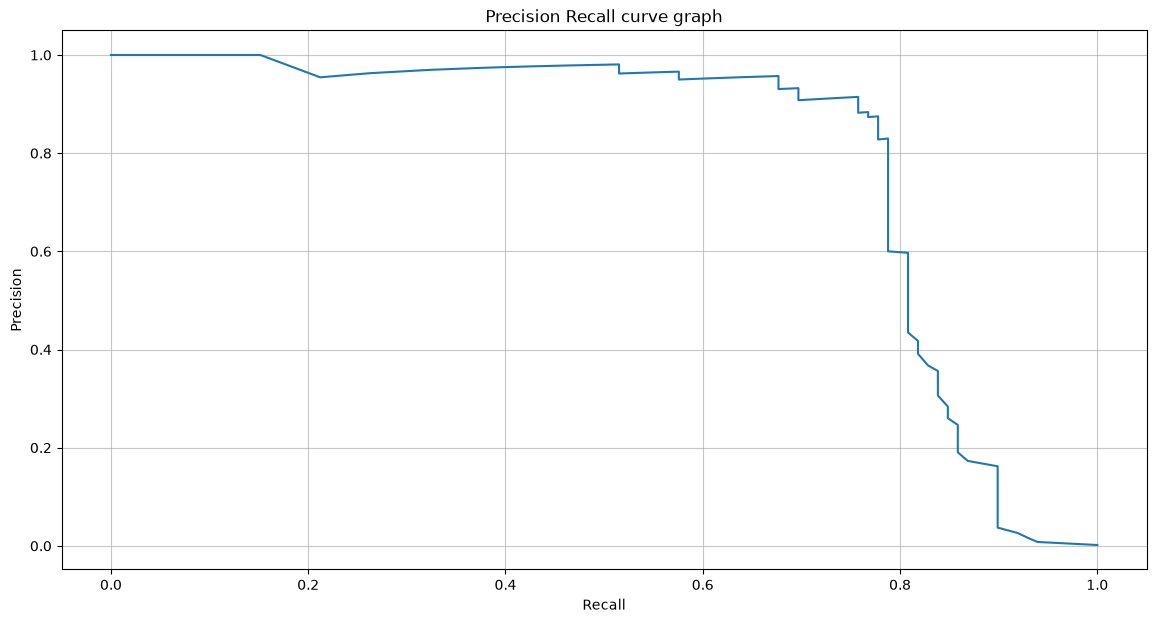

In [23]:
plt.figure(figsize=(14, 7))
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision Recall curve graph")
plt.plot(recall, precision)
plt.grid(alpha=0.7)
plt.show()

Text(0.5, 1.0, 'Random Forest - Confusion Matrix')

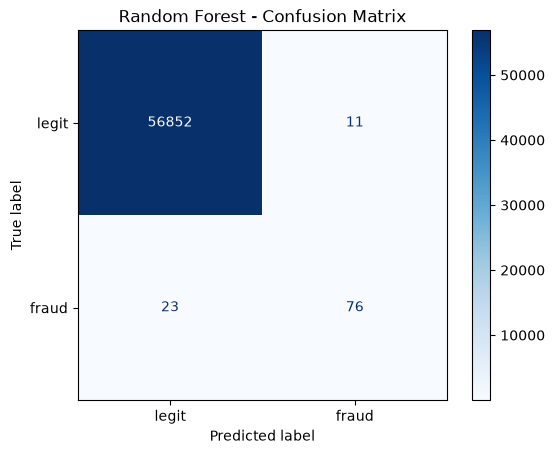

In [26]:
cm = confusion_matrix(y_val, val_predictions)

disp = ConfusionMatrixDisplay(
    cm,
    display_labels=["legit", "fraud"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")

In [35]:
print("Class percentage for validation dataset: ")
print(pd.Series(val_scores).groupby(
    y_val.reset_index(drop=True)
).mean())

Class percentage for validation dataset: 
Class
0    0.003106
1    0.725859
dtype: float64


In [36]:
print("Class percentage for test dataset: ")
print(pd.Series(test_scores).groupby(
    y_test.reset_index(drop=True)
).mean())

Class percentage for test dataset: 
Class
0    0.003218
1    0.782857
dtype: float64


In [39]:
joblib.dump(
    {"model": best_model, "pipeline": rf_pipeline},
    "../models/Credit_Card_Fraud_Detection.joblib"
)

['../models/Credit_Card_Fraud_Detection.joblib']